# Initial conditions for an N-body simulation

Differentiable initial conditions for a DISCO-DJ N-body simulation.

An N-body simulation starts from one Gaussian realisation of the linear matter field. Inflation sets a single random field, the comoving curvature perturbation $\mathcal{R}$, and every species follows from it through a transfer function. DISCO-EB's solutions are per unit initial $\mathcal{R}$, so at the start time

$$
\delta_m(k, \tau_\mathrm{ini}) = T_m(k, \tau_\mathrm{ini}) \, \mathcal{R}(k), \qquad
\langle |\mathcal{R}(k)|^2 \rangle = \frac{2 \pi^2}{k^3} A_s \left(\frac{k}{k_p}\right)^{n_s - 1},
$$

and the particles move off their grid by the Zel'dovich displacement

$$
\boldsymbol{\Psi}(\boldsymbol{k}) = \frac{i \boldsymbol{k}}{k^2} \, \delta_m(k) .
$$

Lengths are in Mpc.

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from discoeb import LCDM, solve_eb

N_GRID = 64  # particles per side
BOX = 500.0  # side of the box, Mpc
TAU_INI = 2000.0  # conformal start time, Mpc: z of about 50

## The grid

The wave numbers of the particle grid, and a solve grid that covers them from the fundamental mode to the corner of the Nyquist cube.

In [2]:
# Wave numbers of the grid, and a solve grid that covers them.
k_axis = 2.0 * np.pi * np.fft.fftfreq(N_GRID, d=BOX / N_GRID)
k_half = 2.0 * np.pi * np.fft.rfftfreq(N_GRID, d=BOX / N_GRID)
k_vec = jnp.stack(jnp.meshgrid(k_axis, k_axis, k_half, indexing="ij"))
k_mag = jnp.sqrt(jnp.sum(k_vec**2, axis=0)).at[0, 0, 0].set(1.0)  # no k = 0 mode
K_SOLVE = np.geomspace(np.pi / BOX, 2.0 * np.sqrt(3.0) * np.pi * N_GRID / BOX, 128)

## From a cosmology to displacements

`solve_eb` keeps the two density contrasts and the scale factor at the start time. Their density-weighted sum is the matter transfer function, interpolated onto the grid's wave numbers. White noise coloured by the primordial spectrum is $\mathcal{R}$ on the grid.

The start is a fixed conformal time, so the derivative below is exact. Its scale factor depends on the cosmology and comes out beside the displacements.

In [3]:
def initial_conditions(cosmology, white_noise):
    """Zel'dovich displacements ``(3, N, N, N)`` in Mpc and the start's scale factor."""

    values = solve_eb(cosmology, K_SOLVE, [TAU_INI], keep=("clxc", "clxb", "a"))
    clxc, clxb, a = values[0, :, :, 0]  # each (n_k,), per unit initial R
    Omegam, Omegab = cosmology.Omegam, cosmology.Omegab
    transfer = ((Omegam - Omegab) * clxc + Omegab * clxb) / Omegam
    transfer = jnp.interp(jnp.log(k_mag), jnp.log(K_SOLVE), transfer)

    # R on the grid: white noise coloured by the primordial spectrum.
    power_R = (
        2.0
        * jnp.pi**2
        / k_mag**3
        * cosmology.A_s
        * (k_mag / cosmology.k_p) ** (cosmology.n_s - 1.0)
    )
    R = jnp.fft.rfftn(white_noise) * jnp.sqrt(power_R / (BOX / N_GRID) ** 3)

    delta = (transfer * R).at[0, 0, 0].set(0.0)
    psi = jnp.fft.irfftn(1j * k_vec * delta / k_mag**2, s=white_noise.shape)
    return psi, a[0]

## The cosmology and the seed

In [4]:
h = 0.6732117
planck = LCDM(
    Omegam=(0.02238280 + 0.1201075) / h**2,
    Omegab=0.02238280 / h**2,
    H0=100.0 * h,
    A_s=2.100549e-9,
    n_s=0.9660499,
    Tcmb=2.7255,
    YHe=0.2454006,
    Neff=3.046,
)
white_noise = jax.random.normal(jax.random.key(42), (N_GRID,) * 3)

## The initial conditions

In [5]:
displacement, a_ini = initial_conditions(planck, white_noise)

## Their derivative

Every step is JAX, so the initial conditions are differentiable in the cosmological parameters at a fixed seed. The derivative of every particle's displacement with respect to $\Omega_m$ costs one forward-sensitivity launch, and DISCO-DJ can carry it on through the simulation.

In [6]:
# The same particles' response to Omega_m, at the same seed.
d_displacement, d_a_ini = jax.jacfwd(
    lambda Omegam: initial_conditions(planck.replace(Omegam=Omegam), white_noise)
)(jnp.asarray(planck.Omegam))

## A slice

The $x$ displacement in the first plane of the box, and its response to $\Omega_m$.

start: a = 0.02017, z = 48.6
rms displacement per axis: 0.222 Mpc
d a / d Omega_m at the start: 0.05043


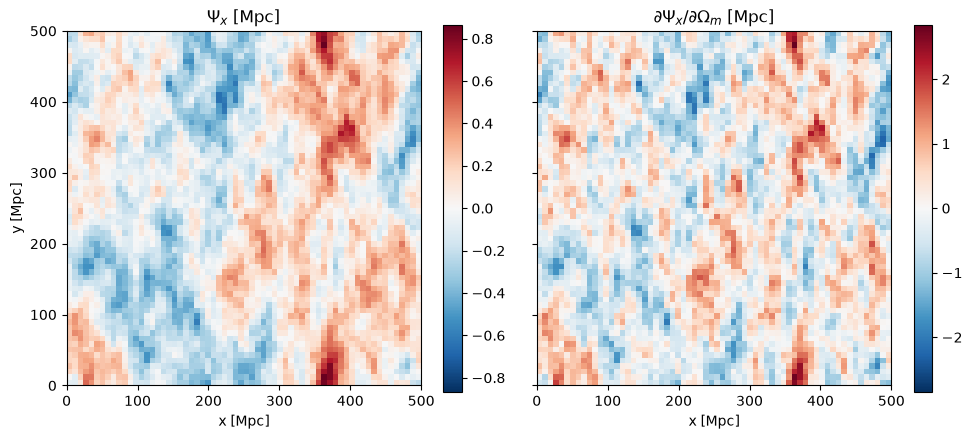

In [7]:
print(f"start: a = {a_ini:.5f}, z = {1.0 / a_ini - 1.0:.1f}")
print(f"rms displacement per axis: {jnp.sqrt(jnp.mean(displacement**2)):.3f} Mpc")
print(f"d a / d Omega_m at the start: {d_a_ini:.5f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
fields = (displacement[0, :, :, 0], d_displacement[0, :, :, 0])
titles = (r"$\Psi_x$ [Mpc]", r"$\partial \Psi_x / \partial \Omega_m$ [Mpc]")
for ax, field, title in zip(axes, fields, titles):
    limit = float(jnp.abs(field).max())
    image = ax.imshow(
        np.asarray(field).T,
        origin="lower",
        extent=(0.0, BOX, 0.0, BOX),
        cmap="RdBu_r",
        vmin=-limit,
        vmax=limit,
    )
    fig.colorbar(image, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("x [Mpc]")
axes[0].set_ylabel("y [Mpc]")
fig.tight_layout()
plt.show()